# 03 — Feature Extraction

Computes the window-level features defined in `src/feature_extraction.py` from the 4 s windows kept in Stage 2.
Features are computed **independently per window** — no statistic is pooled across windows, recordings or subjects — so this step is
leakage-free by construction. All learned transforms (imputation, scaling, selection) happen later inside cross-validation.

Nothing in this notebook is used to *choose* features based on the labels; the label-wise plots are descriptive.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import welch

from data_loader import CHANNELS, CONDITIONS, FS, N_SUBJECTS, load_all
from preprocessing import PreprocessConfig, preprocess
from feature_extraction import (BANDS, TOTAL_BAND, WELCH_NPERSEG, WELCH_NOVERLAP, extract, window_psd,
                                feature_groups, band_power)

FIG_DIR = ROOT / "results" / "figures" / "03_features"; FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT = ROOT / "results" / "03_features"; OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 160, "display.max_columns", 30)
COND_COLOR = {"lo": "#4C72B0", "hi": "#DD8452"}
CFG = PreprocessConfig()
recs = load_all()
proc = {k: preprocess(r, CFG) for k, r in recs.items()}
print("recordings processed:", len(proc))

recordings processed: 96


## 1. Frequency bands and their limits

| Band | Range (Hz) | Rationale |
|---|---|---|
| δ delta | 1–4 | lower edge fixed by the 1 Hz high-pass; at the scalp this band is also where blinks/eye movements put most energy |
| θ theta | 4–8 | frontal(-midline) theta increases with working-memory load and sustained attention (Gevins et al. 1997; Klimesch 1999) |
| α alpha | 8–13 | posterior alpha decreases (desynchronises) with visual attention and task engagement; the 8–13 Hz range covers typical individual alpha peaks |
| β beta | 13–30 | associated with active, alert processing; upper beta overlaps with muscle (EMG) activity |
| γ gamma | 30–45 | upper limit fixed by the headset roll-off (Stage 1); at the scalp, γ is dominated by EMG, so it is treated as a likely artifact marker |

Intervals are half-open, $[f_{lo}, f_{hi})$, so the five bands partition 1–45 Hz exactly (relative powers sum to 1).

**Individual alpha frequency (IAF).** Fixed bands assume everyone's alpha peak lies in 8–13 Hz. We check this on the **rest** recordings
(posterior channels, where alpha is strongest), using the peak of the 7–14 Hz PSD. This is a validation of the band definition, not a feature.

subjects with a detectable posterior alpha peak at rest: 38/48
IAF: median 10.0 Hz, range 7.5–12.5 Hz, within 8–13 Hz: 36


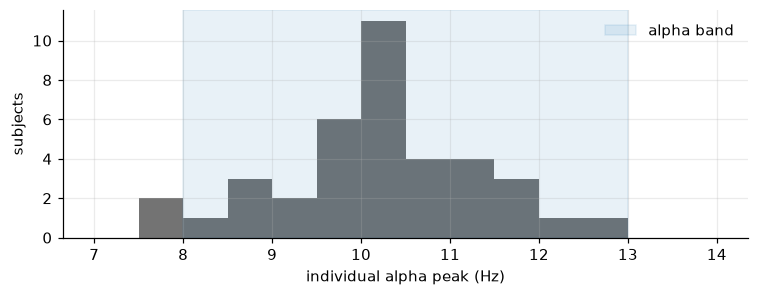

In [2]:
iaf = {}
post = [CHANNELS.index(c) for c in ("O1", "O2", "P7", "P8")]
for s in range(1, N_SUBJECTS + 1):
    p = proc[(s, "lo")]
    W = p.window_data()[:, :, post]
    f, P = window_psd(W)
    m = np.nanmedian(np.nanmean(P, axis=2), axis=0)
    sel = (f >= 7) & (f <= 14)
    # require a genuine local peak (not just the 1/f slope at the band edge)
    i = np.argmax(m[sel]); fi = f[sel][i]
    iaf[s] = fi if 0 < i < sel.sum() - 1 else np.nan
iaf = pd.Series(iaf)
print(f"subjects with a detectable posterior alpha peak at rest: {iaf.notna().sum()}/{len(iaf)}")
print(f"IAF: median {iaf.median():.1f} Hz, range {iaf.min():.1f}–{iaf.max():.1f} Hz, within 8–13 Hz: {iaf.between(8, 13).sum()}")
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(iaf.dropna(), bins=np.arange(7, 14.5, 0.5), color="0.45"); ax.axvspan(8, 13, color="#1f77b4", alpha=0.1, label="alpha band")
ax.set_xlabel("individual alpha peak (Hz)"); ax.set_ylabel("subjects"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "iaf.png", bbox_inches="tight"); plt.show()

## 2. Welch's method inside a 4 s window

For a window of $N=512$ samples, Welch's estimate averages modified periodograms of $K$ overlapping segments $x_k$ of length $L$:

$$\hat P(f) = \frac{1}{K}\sum_{k=1}^{K} \frac{1}{f_s \sum_n w[n]^2}\Big|\sum_{n=0}^{L-1} w[n]\,x_k[n]\,e^{-j2\pi f n/f_s}\Big|^2$$

with a Hann taper $w[n]$ that reduces spectral leakage (side-lobes −31 dB) at the cost of a wider main lobe. The single periodogram has
a standard deviation equal to its mean (χ²₂ distribution) regardless of $N$; averaging $K$ segments reduces the variance roughly by $K$ (less with overlap).

Choice: $L = 256$ (2 s → 0.5 Hz bins, 8 bins in the narrowest 4 Hz bands), 75 % overlap → $K=5$ segments per window. Shorter segments
would give more averaging but only 1 Hz resolution (4 bins for δ and θ); a longer window would reduce the number of training samples and
time resolution. Band power is $\hat P$ integrated over the band (rectangle rule, $\Delta f = 0.5$ Hz); by Parseval the total equals the
signal variance (verified in `tests/test_feature_extraction.py`).

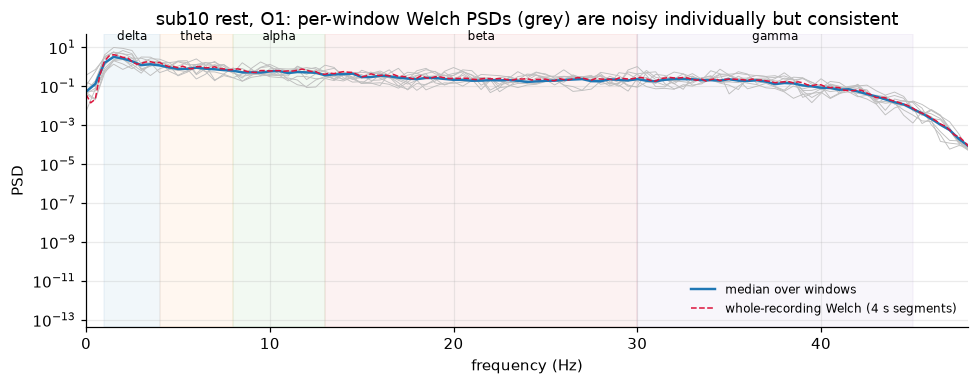

In [3]:
p = proc[(10, "lo")]; W = p.window_data()
f, P = window_psd(W)
fr, Prec = welch(p.x[:, CHANNELS.index("O1")], fs=FS, nperseg=4 * FS)
fig, ax = plt.subplots(figsize=(9, 3.6))
o1 = CHANNELS.index("O1")
for k in range(0, len(W), max(1, len(W) // 8)):
    ax.semilogy(f, P[k, :, o1], color="0.75", lw=0.6)
ax.semilogy(f, np.median(P[:, :, o1], axis=0), color="#1f77b4", lw=1.6, label="median over windows")
ax.semilogy(fr, Prec, color="crimson", lw=1, ls="--", label="whole-recording Welch (4 s segments)")
for b, (lo, hi) in BANDS.items():
    ax.axvspan(lo, hi, alpha=0.06, color="C" + str(list(BANDS).index(b))); ax.text((lo + hi) / 2, ax.get_ylim()[1] * 0.5, b, ha="center", fontsize=8)
ax.set_xlim(0, 48); ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("PSD"); ax.legend(frameon=False, fontsize=8)
ax.set_title("sub10 rest, O1: per-window Welch PSDs (grey) are noisy individually but consistent")
fig.tight_layout(); fig.savefig(FIG_DIR / "window_psd.png", bbox_inches="tight"); plt.show()

## 3. Extract features for all kept windows

In [4]:
meta, feats = [], []
for (s, c), p in proc.items():
    w = p.windows[~p.windows.rejected]
    if len(w) == 0: continue
    feats.append(extract(p.window_data()))
    meta.append(pd.DataFrame({"subject": s, "condition": c, "label": int(c == "hi"), "start_s": w.start_s.values}))
meta = pd.concat(meta, ignore_index=True); F = pd.concat(feats, ignore_index=True)
print("feature matrix:", F.shape, "| windows by condition:", meta.condition.value_counts().to_dict())
groups = feature_groups(F.columns)
print("groups:", {k: len(v) for k, v in groups.items()})
nan_rate = F.isna().mean()
print(f"columns with NaN: {(nan_rate > 0).sum()}; max NaN rate {nan_rate.max():.3%} (from bad channels); inf values: {np.isinf(F.values).sum()}")
display(F.describe().T.sample(12, random_state=0).round(3))

feature matrix: (5554, 282) | windows by condition: {'lo': 2943, 'hi': 2611}
groups: {'time': 84, 'abs_delta': 14, 'abs_theta': 14, 'abs_alpha': 14, 'abs_beta': 14, 'abs_gamma': 14, 'rel_delta': 14, 'rel_theta': 14, 'rel_alpha': 14, 'rel_beta': 14, 'rel_gamma': 14, 'spec_ent': 14, 'ratios': 44}
columns with NaN: 141; max NaN rate 4.681% (from bad channels); inf values: 0


,count,mean,std,min,25%,50%,75%,max
O1_abs_alpha,5554.0,1.027,0.388,0.113,0.764,0.953,1.195,2.769
P8_kurt,5484.0,0.362,1.080,-0.972,-0.163,0.107,0.511,16.655
O1_abs_delta,5554.0,1.585,0.467,0.128,1.265,1.523,1.831,3.521
P7_rel_beta,5554.0,0.160,0.074,0.005,0.107,0.156,0.208,0.463
O2_r_engagement,5554.0,-0.397,0.253,-1.477,-0.543,-0.382,-0.225,0.390
FC5_rel_gamma,5490.0,0.062,0.053,0.001,0.027,0.046,0.081,0.451
F3_r_theta_alpha,5294.0,0.150,0.322,-1.279,-0.025,0.176,0.364,1.222
T8_r_theta_alpha,5554.0,0.074,0.313,-1.312,-0.101,0.108,0.287,0.973
F7_mobility,5497.0,0.405,0.139,0.112,0.299,0.389,0.498,0.965
P8_mobility,5484.0,0.535,0.130,0.141,0.455,0.533,0.613,1.008


## 4. Descriptive view: some classic workload indices, rest vs. test

Window-level distributions pooled over subjects (each subject contributes many correlated windows, so these are not independent samples).

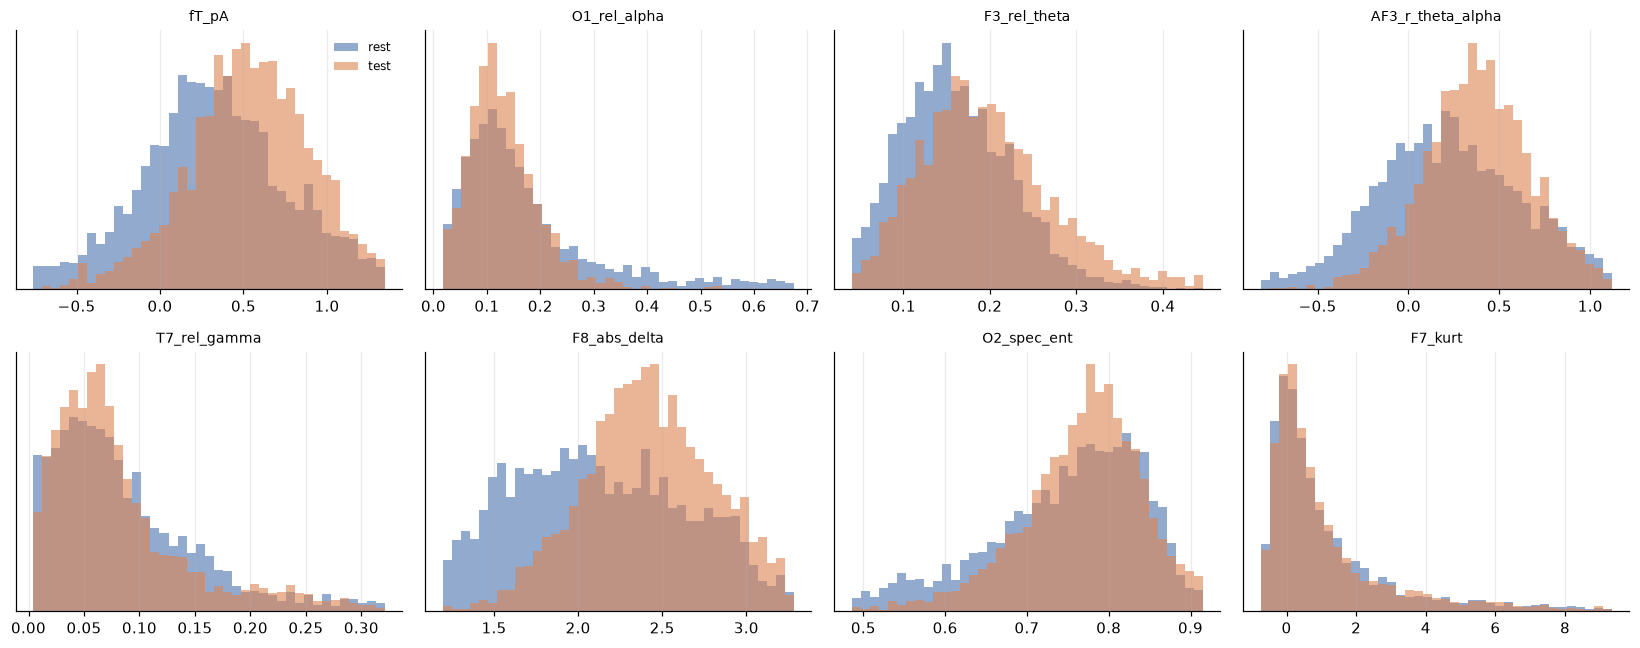

In [5]:
show = ["fT_pA", "O1_rel_alpha", "F3_rel_theta", "AF3_r_theta_alpha", "T7_rel_gamma", "F8_abs_delta", "O2_spec_ent", "F7_kurt"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, col in zip(axes.flat, show):
    v = F[col]; lo_, hi_ = np.nanpercentile(v, [1, 99]); bins = np.linspace(lo_, hi_, 40)
    for c in CONDITIONS:
        ax.hist(v[meta.condition == c].dropna(), bins=bins, alpha=0.6, density=True, color=COND_COLOR[c], label=CONDITIONS[c])
    ax.set_title(col, fontsize=9); ax.set_yticks([])
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "feature_distributions.png", bbox_inches="tight"); plt.show()

## 5. Where does feature variance come from — subject or condition?

For each feature we fit a two-way decomposition of the window values on **subject** and **condition** (recording-level means), reporting
$\eta^2_{subject}$ and $\eta^2_{condition}$ — the share of total variance explained by each factor (sum of squares ratio).
If subject identity explains far more variance than condition, then a model trained on other people must cope with large
inter-individual offsets — the core difficulty of subject-independent EEG decoding and the motivation for Stage 6 (personalisation).

,subject,condition
group,,
rel_theta,0.194,0.061
rel_alpha,0.422,0.030
abs_theta,0.428,0.026
ratios,0.357,0.022
abs_gamma,0.429,0.015
spec_ent,0.306,0.013
abs_alpha,0.563,0.008
rel_gamma,0.360,0.007
abs_beta,0.567,0.007


median over all features: eta2_subject = 0.37, eta2_condition = 0.008
top-10 features by eta2_condition (descriptive only):


,subject,condition,group
F8_abs_theta,0.312,0.215,abs_theta
FC6_abs_theta,0.324,0.140,abs_theta
O2_r_theta_alpha,0.337,0.123,ratios
O2_rel_theta,0.157,0.118,rel_theta
F8_log_var,0.404,0.113,time
FC6_r_theta_alpha,0.355,0.110,ratios
F8_r_theta_beta,0.359,0.107,ratios
FC6_r_theta_beta,0.297,0.105,ratios
AF3_rel_theta,0.216,0.105,rel_theta
F8_abs_beta,0.463,0.098,abs_beta


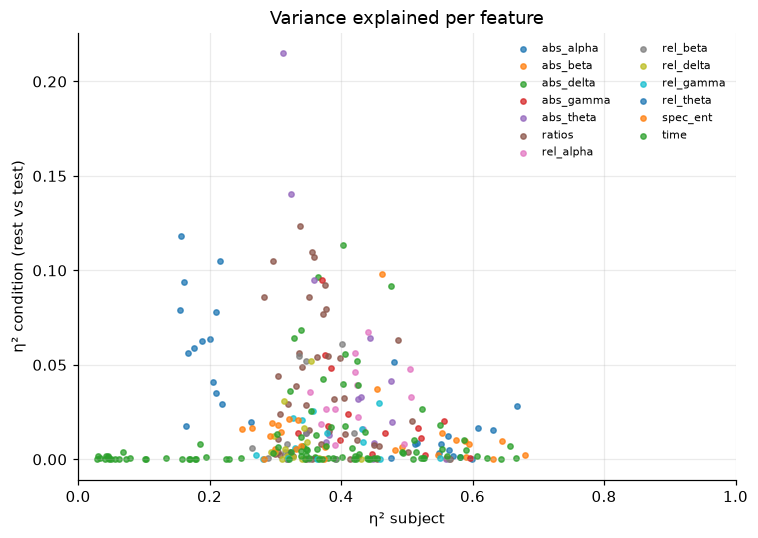

In [6]:
def eta2(values, groups_):
    v = values.astype(float); ok = ~np.isnan(v); v, g = v[ok], groups_[ok]
    grand = v.mean(); ss_tot = ((v - grand) ** 2).sum()
    means = pd.Series(v).groupby(g).transform("mean").values
    return ((means - grand) ** 2).sum() / ss_tot

sub = meta.subject.values; cond = meta.condition.values
eta = pd.DataFrame({"subject": {c: eta2(F[c].values, sub) for c in F}, "condition": {c: eta2(F[c].values, cond) for c in F}})
eta["group"] = [next(g for g, cols in groups.items() if c in cols) for c in eta.index]
summ = eta.groupby("group")[["subject", "condition"]].median().sort_values("condition", ascending=False)
display(summ.round(3))
print(f"median over all features: eta2_subject = {eta.subject.median():.2f}, eta2_condition = {eta.condition.median():.3f}")
print("top-10 features by eta2_condition (descriptive only):")
display(eta.sort_values("condition", ascending=False).head(10).round(3))

fig, ax = plt.subplots(figsize=(7, 5))
for g, d in eta.groupby("group"):
    ax.scatter(d.subject, d.condition, s=12, label=g, alpha=0.75)
ax.set_xlabel("η² subject"); ax.set_ylabel("η² condition (rest vs test)"); ax.set_xlim(0, 1)
ax.legend(frameon=False, fontsize=7, ncol=2); ax.set_title("Variance explained per feature")
fig.tight_layout(); fig.savefig(FIG_DIR / "variance_decomposition.png", bbox_inches="tight"); plt.show()

## 6. Redundancy between features

Absolute band powers across channels share a common per-subject scale (skull thickness, impedance), and relative powers sum to 1 per channel.
Strong collinearity motivates regularised linear models (L2) and tree ensembles, rather than unregularised fits.

feature pairs with |rho| > 0.9: 64 of 39621


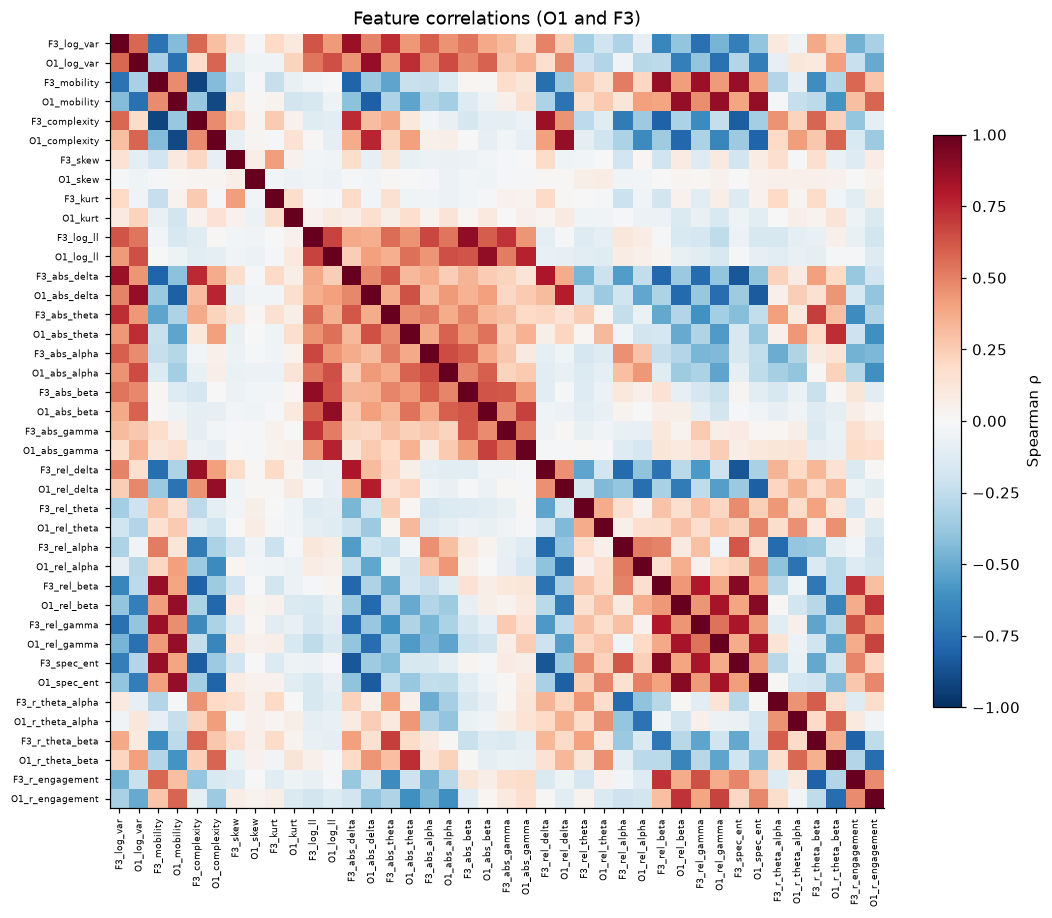

In [7]:
C = F.sample(2000, random_state=0).corr(method="spearman").abs()
upper = C.where(np.triu(np.ones(C.shape, bool), 1))
print(f"feature pairs with |rho| > 0.9: {(upper > 0.9).sum().sum()} of {upper.count().sum()}")
sel = [c for c in F.columns if c.startswith(("O1_", "F3_"))]
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(F[sel].corr(method="spearman"), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(sel)), sel, rotation=90, fontsize=6); ax.set_yticks(range(len(sel)), sel, fontsize=6); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman ρ"); ax.set_title("Feature correlations (O1 and F3)")
fig.tight_layout(); fig.savefig(FIG_DIR / "feature_correlation.png", bbox_inches="tight"); plt.show()

## 7. Save

In [8]:
FEAT = ROOT / "data" / "features"; FEAT.mkdir(parents=True, exist_ok=True)
table = pd.concat([meta, F], axis=1)
table.to_csv(FEAT / "features.csv.gz", index=False, float_format="%.6g")
eta.to_csv(OUT / "variance_decomposition.csv")
summary = {"n_windows": int(len(table)), "n_features": int(F.shape[1]), "groups": {k: len(v) for k, v in groups.items()},
           "windows_by_condition": meta.condition.value_counts().to_dict(),
           "bands_hz": BANDS, "total_band_hz": TOTAL_BAND, "welch": {"nperseg": WELCH_NPERSEG, "noverlap": WELCH_NOVERLAP, "window": "hann"},
           "iaf_rest_hz": {"n_detected": int(iaf.notna().sum()), "median": float(iaf.median()), "min": float(iaf.min()), "max": float(iaf.max())},
           "eta2_median": {"subject": float(eta.subject.median()), "condition": float(eta.condition.median())}}
with open(OUT / "summary.json", "w") as fh:
    json.dump(summary, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved", (FEAT / "features.csv.gz").relative_to(ROOT), f"{(FEAT / 'features.csv.gz').stat().st_size / 1e6:.1f} MB")

saved data/features/features.csv.gz 5.7 MB


## 8. Findings

- **Feature matrix.** 5 554 windows × 282 features (14 channels × 20 + 2 regional). NaN only where a channel was marked bad (≤ 4.7 % of a column);
  no infinities.
- **Band limits.** A posterior alpha peak is detectable at rest in 38/48 subjects; individual peaks range 7.5–12.5 Hz (median 10.0 Hz), so the fixed
  8–13 Hz alpha band contains nearly all of them. Subjects with peaks near 8 Hz will have some alpha power leaking into "theta" — a known limitation of fixed bands.
- **Subject vs condition variance.** Median η²(subject) = 0.37 vs η²(condition) = 0.008. Subject identity explains far more feature variance than
  rest-vs-test. This predicts that subject-independent models will be much weaker than within-subject ones and motivates baseline normalisation (Stage 6).
- **Most condition-related feature groups** (median η²): relative theta (0.061), relative alpha (0.030), absolute theta, ratios. Time-domain features
  carry almost no condition variance (0.001). The single strongest features are theta at **F8 and FC6** (right fronto-temporal) and the theta/alpha ratio at O2.
  F8 is adjacent to the right eye; the ablations in Stage 4 will check how much of this is ocular.
- **Redundancy.** 64 feature pairs have |ρ| > 0.9 (mostly Hjorth/line-length vs. log-variance and absolute vs. total power), supporting regularised models.